# Laboratorio 11 · Guía 3 — Árboles y Ensambles de Regresión: Random Forest, Gradient Boosting, XGBoost y LightGBM

**Curso:** Minería de Datos (DM + AIAP) · FISI · UNMSM · Semestre 2026-II · **Semana 12 del sílabo (Tema 12: Modelos de Regresión)**
**Docente:** Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Fase CRISP-DM:** Modelado · Evaluación.

**Pregunta de negocio:** los modelos lineales de las Guías 1 y 2 suponen que el efecto de cada variable es **constante**. En el mercado, el efecto del **VIX** sobre el riesgo de la próxima semana **no** es el mismo en calma que en pánico (**no linealidad**) y depende de la volatilidad reciente (**interacción**). ¿Cuánto ganan los **árboles** y sus **ensambles** frente a Ridge/Lasso? ¿Y cuándo **fallan** (extrapolación, sobreajuste, ruido puro)? Adelanto honesto: en el Mundo 2 ganan por mucho; en la volatilidad real **empatan** con Ridge; en el retorno diario **nadie** gana.

**Estructura:** Parte I, cómo parte un **árbol de regresión** · Parte II, **laboratorio de contraste sintético** (**Mundo 2**): no linealidad, extrapolación y sobreajuste · Parte III, **pronóstico de la volatilidad** de SPY con seis modelos de árboles, búsqueda de hiperparámetros cronológica, **importancia por permutación** y **dependencia parcial** (**Mundo 3**) · Parte IV, **XGBoost** contra el **retorno de mañana** (**Mundo 1**).

> **Enfoque didáctico:** cada paso en su propia celda con sus `print`. Semilla `SEMILLA = 2026`. Precios hasta el 11-nov-2026.

# PARTE I — Cómo Parte un Árbol de Regresión

## 1. Librerías, Semilla y Datos

Un **árbol de regresión** divide el espacio de las variables en **regiones** rectangulares y predice en cada una la **media** de y. Cada partición se elige para **minimizar la suma de cuadrados** de los residuos. Un **Random Forest** promedia muchos árboles entrenados con **bootstrap** y **subconjuntos aleatorios de variables** (reduce la varianza); el **Gradient Boosting** entrena árboles **pequeños en secuencia**, cada uno sobre los **residuos** del anterior (reduce el sesgo). **XGBoost** y **LightGBM** son implementaciones optimizadas del boosting con **regularización** y **paralelismo**.

In [1]:
# Librerías del laboratorio
import warnings

warnings.filterwarnings("ignore")
import time
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficos
import yfinance as yf  # precios de Yahoo Finance
import sklearn, xgboost, lightgbm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    RandomizedSearchCV,
)
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.datasets import make_friedman1

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
print(
    "scikit-learn",
    sklearn.__version__,
    "| XGBoost",
    xgboost.__version__,
    "| LightGBM",
    lightgbm.__version__,
)

scikit-learn 1.3.1 | XGBoost 3.2.0 | LightGBM 4.5.0


In [2]:
# Precios de cierre ajustado de 28 activos (Yahoo Finance). Plan B: CSV de respaldo del curso (carpeta D03)
TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = "26.11.12.cierres_ajustados_28_activos_2010-01-04_2026-11-11.csv"
try:
    precios = yf.download(
        TICKERS, start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )["Close"].reindex(columns=TICKERS)
except Exception as e:
    precios = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if precios.empty or precios["SPY"].notna().sum() < 4000:
    precios = pd.read_csv(
        ARCH, index_col=0, parse_dates=True
    )  # súbalo a Colab si Yahoo no responde
    print("Se usó el CSV de respaldo:", ARCH)
precios.index = pd.to_datetime(precios.index)
print(
    "Dimensiones:",
    precios.shape,
    "| desde",
    precios.index.min().date(),
    "hasta",
    precios.index.max().date(),
)
print(
    "Días con precio de SPY:",
    int(precios["SPY"].notna().sum()),
    "| último cierre de SPY:",
    round(float(precios["SPY"].iloc[-1]), 2),
)

Dimensiones: (4243, 28) | desde 2010-01-04 hasta 2026-11-11
Días con precio de SPY: 4241 | último cierre de SPY: 759.81


In [3]:
# Precios OHLCV (apertura, máximo, mínimo, cierre, volumen) ajustados de SPY. Plan B: CSV de respaldo (D03)
ARCH_SPY = "26.11.12.SPY_OHLCV_ajustado_2010-01-04_2026-11-11.csv"
try:
    spy = yf.download(
        "SPY", start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )
    spy.columns = [c[0] if isinstance(c, tuple) else c for c in spy.columns]
    spy = spy[["Open", "High", "Low", "Close", "Volume"]]
except Exception as e:
    spy = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if spy.empty or len(spy) < 4000:
    spy = pd.read_csv(ARCH_SPY, index_col=0, parse_dates=True)
    print("Se usó el CSV de respaldo:", ARCH_SPY)
spy.index = pd.to_datetime(spy.index)
print(
    "SPY OHLCV:",
    spy.shape,
    "| desde",
    spy.index.min().date(),
    "hasta",
    spy.index.max().date(),
)
print(spy.tail(3).round(2))

SPY OHLCV: (4241, 5) | desde 2010-01-04 hasta 2026-11-11
              Open    High     Low   Close    Volume
Date                                                
2026-11-09  741.95  755.42  741.03  752.69  50281200
2026-11-10  747.94  752.14  744.86  749.92  40698600
2026-11-11  756.80  762.51  754.90  759.81  38854000


## 2. Un Árbol Pequeño Sobre una Relación No Lineal (Ilustración)

> **Observación:** datos **sintéticos** (y = sen(x) + ruido) para ver las **particiones** del árbol.

Umbrales de corte del árbol: [2.747 3.106 3.617]
Valor predicho en cada hoja: [ 0.754  0.242 -0.164 -0.78 ]


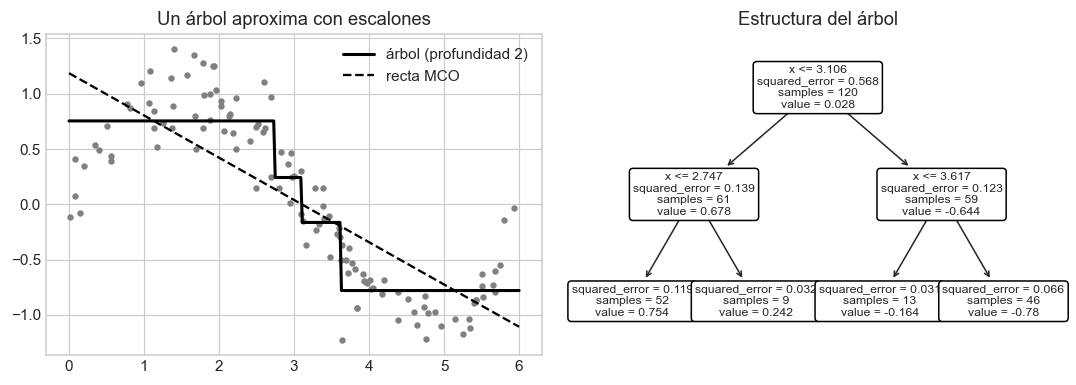

In [4]:
# Árbol de profundidad 2 sobre y = sen(x): tres cortes, cuatro regiones, cuatro medias
x_il = np.sort(rng.uniform(0, 6, 120))
y_il = np.sin(x_il) + rng.normal(0, 0.2, 120)
arbol2 = DecisionTreeRegressor(max_depth=2, random_state=SEMILLA).fit(
    x_il.reshape(-1, 1), y_il
)
umbrales = sorted(t for t in arbol2.tree_.threshold if t != -2)
print("Umbrales de corte del árbol:", np.round(umbrales, 3))
print(
    "Valor predicho en cada hoja:",
    np.round(arbol2.tree_.value[arbol2.tree_.children_left == -1].ravel(), 3),
)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
xx = np.linspace(0, 6, 300).reshape(-1, 1)
ax[0].scatter(x_il, y_il, s=10, color="gray")
ax[0].plot(
    xx, arbol2.predict(xx), color="black", linewidth=2, label="árbol (profundidad 2)"
)
ax[0].plot(
    xx,
    LinearRegression().fit(x_il.reshape(-1, 1), y_il).predict(xx),
    color="black",
    linestyle="--",
    label="recta MCO",
)
ax[0].set_title("Un árbol aproxima con escalones")
ax[0].legend()
plot_tree(arbol2, ax=ax[1], feature_names=["x"], filled=False, rounded=True, fontsize=8)
ax[1].set_title("Estructura del árbol")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el árbol convierte la curva en **cuatro escalones** (cuatro **hojas** con su **media**). Una **recta** no puede seguir la forma del seno. Con más profundidad los escalones se afinan, pero también empiezan a seguir el **ruido** (sobreajuste, sección 5).

# PARTE II — Laboratorio de Contraste Sintético (Mundo 2)

> **Observación:** los datos de esta parte son **sintéticos** con semilla **2026**; sirven para aislar cada fenómeno y no se reportan como hallazgos de negocio.

## 3. Fenómeno 1: con No Linealidad e Interacciones los Ensambles Ganan a la Regresión Lineal

El generador **Friedman #1** tiene 10 variables, de las cuales 5 importan: **y = 10·sen(π·x₁·x₂) + 20·(x₃ − 0,5)² + 10·x₄ + 5·x₅ + ruido**. Incluye una **interacción** (x₁·x₂) y una **curvatura** (x₃²).

In [5]:
# Friedman #1: 800 observaciones, división aleatoria 70/30 (datos i.i.d., no hay tiempo)
X_f, y_f = make_friedman1(n_samples=800, n_features=10, noise=1.0, random_state=SEMILLA)
Xf_ent, Xf_pru, yf_ent, yf_pru = train_test_split(
    X_f, y_f, test_size=0.3, random_state=SEMILLA
)
modelos_f = {
    "Regresión lineal": LinearRegression(),
    "Árbol (profundidad 6)": DecisionTreeRegressor(max_depth=6, random_state=SEMILLA),
    "Random Forest (300)": RandomForestRegressor(
        n_estimators=300, random_state=SEMILLA, n_jobs=-1
    ),
    "Gradient Boosting (300)": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEMILLA
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, random_state=SEMILLA
    ),
    "XGBoost (300)": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
    "LightGBM (300)": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        random_state=SEMILLA,
        verbose=-1,
    ),
}
filas = []
for nombre, m in modelos_f.items():
    t0 = time.time()
    m.fit(Xf_ent, yf_ent)
    t = time.time() - t0
    filas.append(
        [
            nombre,
            r2_score(yf_ent, m.predict(Xf_ent)),
            r2_score(yf_pru, m.predict(Xf_pru)),
            mean_absolute_error(yf_pru, m.predict(Xf_pru)),
            t,
        ]
    )
tabla_f = pd.DataFrame(
    filas, columns=["modelo", "R2_entren", "R2_prueba", "MAE_prueba", "segundos"]
)
print(tabla_f.round(4).to_string(index=False))

                 modelo  R2_entren  R2_prueba  MAE_prueba  segundos
       Regresión lineal     0.7001     0.6350      2.1116    0.0000
  Árbol (profundidad 6)     0.8560     0.5570      2.4772    0.0075
    Random Forest (300)     0.9731     0.7701      1.7464    0.9402
Gradient Boosting (300)     0.9804     0.8643      1.2815    1.5667
   HistGradientBoosting     0.9972     0.8702      1.2486    0.9510
          XGBoost (300)     0.9820     0.8894      1.1665    0.2946
         LightGBM (300)     0.9953     0.8866      1.1822    0.1095


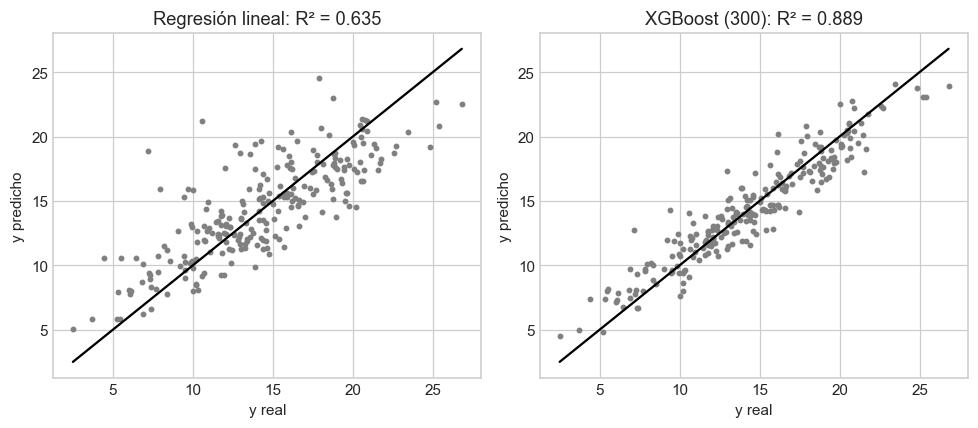

In [6]:
# Valores reales frente a predichos en la prueba: lineal frente a XGBoost
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, nombre in zip(ax, ["Regresión lineal", "XGBoost (300)"]):
    p = modelos_f[nombre].predict(Xf_pru)
    a.scatter(yf_pru, p, s=8, color="gray")
    a.plot([yf_pru.min(), yf_pru.max()], [yf_pru.min(), yf_pru.max()], color="black")
    a.set_xlabel("y real")
    a.set_ylabel("y predicho")
    a.set_title(f"{nombre}: R² = {r2_score(yf_pru, p):.3f}")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** la **regresión lineal** no puede representar **sen(π·x₁·x₂)** ni **(x₃ − 0,5)²** y se queda con un R² de prueba claramente menor; los **ensambles** (Random Forest, Gradient Boosting, XGBoost, LightGBM) capturan la curvatura y la interacción. El **árbol solo** mejora a la recta pero queda por debajo de los ensambles (alta **varianza**). Observe el **R² de entrenamiento** del Random Forest (cerca de 1): los bosques **memorizan** el entrenamiento y se evalúan **siempre fuera de muestra**.

## 4. Fenómeno 2: los Árboles No Extrapolan

Se entrena con **x entre 0 y 10** y se predice con **x entre 10 y 14** (fuera del rango). La relación es **y = 0,8·x + 2·sen(x)**: la recta captura la **tendencia** y los árboles, la **forma**... hasta donde vieron datos.

In [7]:
# Entrenamiento dentro del rango [0, 10]; prueba por interpolación [0, 10] y por extrapolación [10, 14]
x_tr = np.sort(rng.uniform(0, 10, 400))
y_tr = 0.8 * x_tr + 2 * np.sin(x_tr) + rng.normal(0, 0.5, 400)
x_in = np.sort(rng.uniform(0, 10, 200))
y_in = 0.8 * x_in + 2 * np.sin(x_in) + rng.normal(0, 0.5, 200)
x_ex = np.sort(rng.uniform(10, 14, 200))
y_ex = 0.8 * x_ex + 2 * np.sin(x_ex) + rng.normal(0, 0.5, 200)
modelos_x = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=SEMILLA, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEMILLA
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
}
filas = []
for nombre, m in modelos_x.items():
    m.fit(x_tr.reshape(-1, 1), y_tr)
    filas.append(
        [
            nombre,
            mean_absolute_error(y_in, m.predict(x_in.reshape(-1, 1))),
            mean_absolute_error(y_ex, m.predict(x_ex.reshape(-1, 1))),
        ]
    )
tabla_x = pd.DataFrame(
    filas, columns=["modelo", "MAE_interpolacion_[0,10]", "MAE_extrapolacion_[10,14]"]
)
print(tabla_x.round(3).to_string(index=False))

           modelo  MAE_interpolacion_[0,10]  MAE_extrapolacion_[10,14]
 Regresión lineal                     1.216                      1.488
    Random Forest                     0.498                      2.423
Gradient Boosting                     0.443                      2.371
          XGBoost                     0.411                      2.445


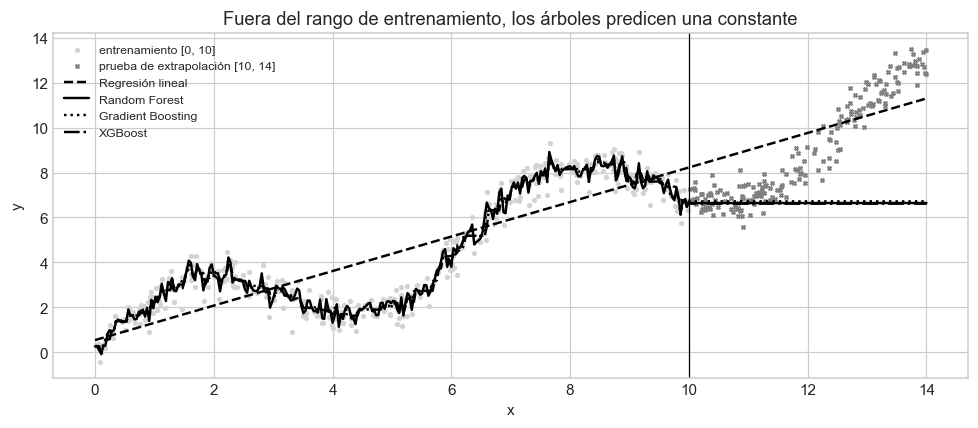

In [8]:
# Gráfico: dentro del rango los árboles ganan; fuera del rango se quedan planos
xx = np.linspace(0, 14, 400).reshape(-1, 1)
plt.figure(figsize=(9, 4))
plt.scatter(x_tr, y_tr, s=6, color="lightgray", label="entrenamiento [0, 10]")
plt.scatter(
    x_ex, y_ex, s=6, color="gray", marker="x", label="prueba de extrapolación [10, 14]"
)
estilos = {
    "Regresión lineal": "--",
    "Random Forest": "-",
    "Gradient Boosting": ":",
    "XGBoost": "-.",
}
for nombre, m in modelos_x.items():
    plt.plot(
        xx, m.predict(xx), estilos[nombre], color="black", linewidth=1.6, label=nombre
    )
plt.axvline(10, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(fontsize=8, loc="upper left")
plt.title("Fuera del rango de entrenamiento, los árboles predicen una constante")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** dentro del rango, los ensambles siguen la onda y su **MAE** es menor que el de la recta. Fuera del rango, **todos los árboles predicen una constante** (la media de la última hoja) y su error se dispara; la **recta** al menos sigue la tendencia. **Moraleja financiera:** un modelo de árboles entrenado en años de **calma** no puede predecir un nivel de volatilidad **nunca visto** (marzo de 2020); por eso en el Mundo 3 se evalúa en un período que incluye episodios extremos.

## 5. Fenómeno 3: Sobreajuste según la Profundidad

Profundidad con mejor R² de prueba: 4 | R² prueba = 0.5666 | R² entrenamiento a esa profundidad = 0.7102
Profundidad 20: R² entrenamiento = 1.0000 | R² prueba = 0.5035


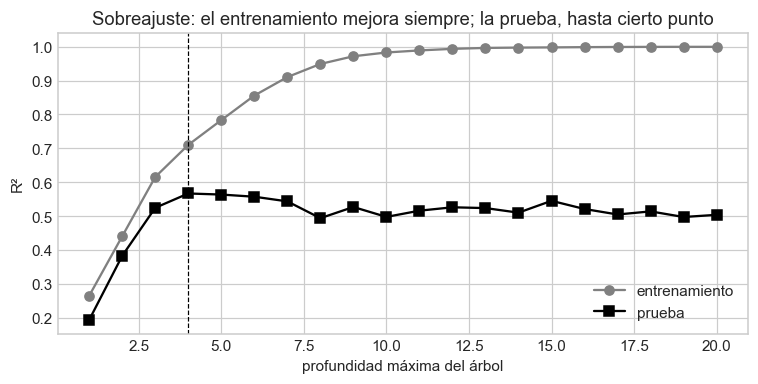

In [9]:
# Curva de complejidad: R² de entrenamiento y de prueba frente a la profundidad del árbol (Friedman #1)
profundidades = list(range(1, 21))
r2_e, r2_p = [], []
for d in profundidades:
    a = DecisionTreeRegressor(max_depth=d, random_state=SEMILLA).fit(Xf_ent, yf_ent)
    r2_e.append(r2_score(yf_ent, a.predict(Xf_ent)))
    r2_p.append(r2_score(yf_pru, a.predict(Xf_pru)))
mejor = profundidades[int(np.argmax(r2_p))]
print(
    "Profundidad con mejor R² de prueba:",
    mejor,
    f"| R² prueba = {max(r2_p):.4f} | R² entrenamiento a esa profundidad = "
    f"{r2_e[mejor - 1]:.4f}",
)
print(f"Profundidad 20: R² entrenamiento = {r2_e[-1]:.4f} | R² prueba = {r2_p[-1]:.4f}")
plt.figure(figsize=(7, 3.6))
plt.plot(profundidades, r2_e, "o-", color="gray", label="entrenamiento")
plt.plot(profundidades, r2_p, "s-", color="black", label="prueba")
plt.axvline(mejor, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("profundidad máxima del árbol")
plt.ylabel("R²")
plt.legend()
plt.title("Sobreajuste: el entrenamiento mejora siempre; la prueba, hasta cierto punto")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el **R² de entrenamiento** sube hasta **1,0** (un árbol sin límite memoriza cada punto) mientras el **R² de prueba** alcanza un máximo en una profundidad intermedia y luego **baja**: es la **compensación sesgo–varianza**. Por eso los hiperparámetros (**max_depth**, **min_samples_leaf**, **learning_rate**, **n_estimators**) se eligen con **validación**, nunca con el entrenamiento ni con la prueba final.

# PARTE III — Pronóstico de la Volatilidad de SPY con Árboles y Ensambles (Mundo 3)

**Conjunto de datos:** SPY (OHLCV) y VIX de **Yahoo Finance**, 2012–2026; las **10 variables básicas** de la Guía 2 (retornos rezagados, volatilidades a 5, 22 y 66 días, VIX y su variación, volatilidad de Parkinson, cambio de volumen) y el mismo **objetivo**: volatilidad realizada de los próximos **5 días**. División cronológica **70/30** (prueba desde junio de 2022). Los árboles **no necesitan** escalado ni expansión polinómica: descubren las **interacciones** solos.

## 6. Variables, Objetivo y Referencias

In [10]:
# Variables causales y objetivo futuro (mismas que la Guía 2)
r = (np.log(spy["Close"]).diff() * 100).loc["2012-01-01":]
vix = precios["^VIX"].reindex(r.index).ffill()
base = pd.DataFrame(
    {
        "ret_t": r,
        "ret_t1": r.shift(1),
        "abs_ret": r.abs(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(),
        "parkinson": (
            np.log(spy["High"] / spy["Low"]).loc[r.index] / np.sqrt(4 * np.log(2)) * 100
        ),
    }
)
base["d_volumen"] = np.log(spy["Volume"]).diff().loc[r.index]
base["objetivo"] = r.shift(-5).rolling(5).std()
base = base.replace([np.inf, -np.inf], np.nan).dropna()
VARS = [c for c in base.columns if c != "objetivo"]
corte = int(len(base) * 0.7)
ent, pru = base.iloc[:corte], base.iloc[corte:]
X_ent, y_ent, X_pru, y_pru = ent[VARS], ent["objetivo"], pru[VARS], pru["objetivo"]
print(
    "Entrenamiento:",
    len(ent),
    "días hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "días desde",
    pru.index.min().date(),
)
print(
    "Referencia persistencia (vol_5): MAE prueba = "
    f"{mean_absolute_error(y_pru, pru['vol_5']):.4f} | R² = "
    f"{r2_score(y_pru, pru['vol_5']):.4f}"
)
ridge_ref = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_ent, y_ent)
print(
    "Referencia Ridge (10 variables, alpha = 10): MAE prueba = "
    f"{mean_absolute_error(y_pru, ridge_ref.predict(X_pru)):.4f} | R² = "
    f"{r2_score(y_pru, ridge_ref.predict(X_pru)):.4f}"
)

Entrenamiento: 2566 días hasta 2022-06-15 | Prueba: 1101 días desde 2022-06-16
Referencia persistencia (vol_5): MAE prueba = 0.3907 | R² = -0.1657
Referencia Ridge (10 variables, alpha = 10): MAE prueba = 0.2944 | R² = 0.3547


## 7. Seis Modelos de Árboles con Hiperparámetros Razonables

In [11]:
# Seis modelos con hiperparámetros iniciales (sin búsqueda); se comparan en entrenamiento y prueba
modelos_v = {
    "Árbol (profundidad 4)": DecisionTreeRegressor(
        max_depth=4, min_samples_leaf=30, random_state=SEMILLA
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=20,
        max_features=0.6,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        min_samples_leaf=20,
        random_state=SEMILLA,
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=400,
        learning_rate=0.03,
        max_depth=4,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=SEMILLA,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=20,
        reg_lambda=5,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=SEMILLA,
        verbose=-1,
    ),
}
filas = []
for nombre, m in modelos_v.items():
    t0 = time.time()
    m.fit(X_ent, y_ent)
    t = time.time() - t0
    pe, pp = m.predict(X_ent), m.predict(X_pru)
    filas.append(
        [
            nombre,
            r2_score(y_ent, pe),
            r2_score(y_pru, pp),
            mean_absolute_error(y_pru, pp),
            t,
        ]
    )
tabla_v = pd.DataFrame(
    filas, columns=["modelo", "R2_entren", "R2_prueba", "MAE_prueba", "segundos"]
).sort_values("MAE_prueba")
print(tabla_v.round(4).to_string(index=False))

               modelo  R2_entren  R2_prueba  MAE_prueba  segundos
        Random Forest     0.6393     0.3280      0.2915    1.7662
              XGBoost     0.7072     0.2474      0.2978    0.2601
 HistGradientBoosting     0.7291     0.2789      0.3019    0.3686
    Gradient Boosting     0.7271     0.1728      0.3029    6.9988
Árbol (profundidad 4)     0.5682     0.2254      0.3063    0.0225
             LightGBM     0.7201     0.2516      0.3090    0.1281


## 8. Búsqueda de Hiperparámetros con Validación Cronológica (XGBoost y Random Forest)

`RandomizedSearchCV` con `TimeSeriesSplit(n_splits=5, gap=5)` **solo dentro del entrenamiento**: la prueba se mira **una vez**, al final.

In [12]:
# Búsqueda aleatoria de 25 combinaciones para XGBoost con validación cronológica
tscv5 = TimeSeriesSplit(n_splits=5, gap=5)
rej_xgb = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 6],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [5, 20, 50],
    "reg_lambda": [1, 5, 20],
}
bus_xgb = RandomizedSearchCV(
    XGBRegressor(random_state=SEMILLA, n_jobs=-1),
    rej_xgb,
    n_iter=25,
    cv=tscv5,
    scoring="neg_mean_absolute_error",
    random_state=SEMILLA,
    n_jobs=1,
).fit(X_ent, y_ent)
print("Mejores hiperparámetros XGBoost:", bus_xgb.best_params_)
print(f"MAE de validación cronológica = {-bus_xgb.best_score_:.4f}")
xgb_mejor = bus_xgb.best_estimator_
print(
    f"XGBoost ajustado: R² prueba = {r2_score(y_pru, xgb_mejor.predict(X_pru)):.4f} | "
    f"MAE prueba = {mean_absolute_error(y_pru, xgb_mejor.predict(X_pru)):.4f}"
)

Mejores hiperparámetros XGBoost: {'subsample': 0.6, 'reg_lambda': 20, 'n_estimators': 200, 'min_child_weight': 20, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
MAE de validación cronológica = 0.3531
XGBoost ajustado: R² prueba = 0.3411 | MAE prueba = 0.2887


In [13]:
# Búsqueda aleatoria de 20 combinaciones para Random Forest
rej_rf = {
    "n_estimators": [200, 400],
    "max_depth": [4, 6, 8, 12, None],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features": [0.3, 0.6, 1.0],
}
bus_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEMILLA, n_jobs=-1),
    rej_rf,
    n_iter=20,
    cv=tscv5,
    scoring="neg_mean_absolute_error",
    random_state=SEMILLA,
    n_jobs=1,
).fit(X_ent, y_ent)
print("Mejores hiperparámetros Random Forest:", bus_rf.best_params_)
print(f"MAE de validación cronológica = {-bus_rf.best_score_:.4f}")
rf_mejor = bus_rf.best_estimator_
print(
    "Random Forest ajustado: R² prueba = "
    f"{r2_score(y_pru, rf_mejor.predict(X_pru)):.4f} | MAE prueba = "
    f"{mean_absolute_error(y_pru, rf_mejor.predict(X_pru)):.4f}"
)

Mejores hiperparámetros Random Forest: {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 8}
MAE de validación cronológica = 0.3496
Random Forest ajustado: R² prueba = 0.3167 | MAE prueba = 0.2949


In [14]:
# Tabla final de comparación en la prueba (una sola mirada): referencias, lineales y ensambles ajustados
finales = {
    "Persistencia (vol_5)": pru["vol_5"].values,
    "Ridge (10 variables)": ridge_ref.predict(X_pru),
    "Random Forest ajustado": rf_mejor.predict(X_pru),
    "XGBoost ajustado": xgb_mejor.predict(X_pru),
    "LightGBM": modelos_v["LightGBM"].predict(X_pru),
    "Gradient Boosting": modelos_v["Gradient Boosting"].predict(X_pru),
}
tabla_final = pd.DataFrame(
    [
        [
            k,
            r2_score(y_pru, v),
            mean_absolute_error(y_pru, v),
            np.sqrt(np.mean((y_pru - v) ** 2)),
        ]
        for k, v in finales.items()
    ],
    columns=["modelo", "R2_prueba", "MAE_prueba", "RMSE_prueba"],
).sort_values("MAE_prueba")
print(tabla_final.round(4).to_string(index=False))

                modelo  R2_prueba  MAE_prueba  RMSE_prueba
      XGBoost ajustado     0.3411      0.2887       0.4595
  Ridge (10 variables)     0.3547      0.2944       0.4548
Random Forest ajustado     0.3167      0.2949       0.4679
     Gradient Boosting     0.1728      0.3029       0.5149
              LightGBM     0.2516      0.3090       0.4897
  Persistencia (vol_5)    -0.1657      0.3907       0.6112


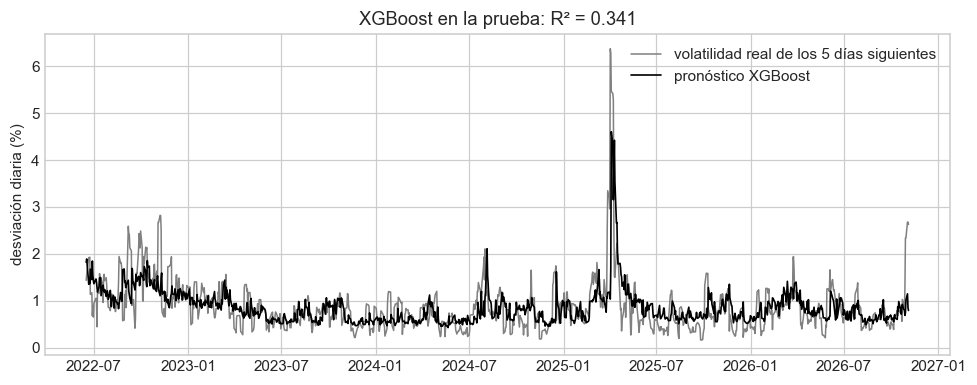

In [15]:
# Volatilidad real y pronosticada por XGBoost en la prueba (incluye el episodio de abril de 2025)
p_xgb = xgb_mejor.predict(X_pru)
plt.figure(figsize=(9, 3.6))
plt.plot(
    pru.index,
    y_pru.values,
    color="gray",
    linewidth=1,
    label="volatilidad real de los 5 días siguientes",
)
plt.plot(pru.index, p_xgb, color="black", linewidth=1.1, label="pronóstico XGBoost")
plt.ylabel("desviación diaria (%)")
plt.legend()
plt.title(f"XGBoost en la prueba: R² = {r2_score(y_pru, p_xgb):.3f}")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** sin ajuste, los seis modelos de árboles **sobreajustan** (R² de entrenamiento 0,57–0,73 frente a 0,17–0,33 en prueba) y **ninguno** alcanza a la humilde **Ridge** con 10 variables (R² 0,355). Con la búsqueda cronológica, **XGBoost** logra el mejor **MAE** de prueba (**0,289**) pero su **R²** (0,341) sigue por debajo de Ridge (0,355): en la práctica, **empatan**. Todos superan con holgura a la **persistencia** (R² negativo). **Lección:** la señal de la volatilidad es principalmente **monótona** (más VIX hoy → más riesgo mañana) y una recta ya la captura; los ensambles solo pagan cuando hay **no linealidades fuertes** (Mundo 2). Observe cómo todos los modelos **subestiman** el pico de **abril de 2025**: es el límite de la extrapolación de la sección 4.

## 9. ¿Qué Variables Importan? Impureza frente a Permutación

           impureza_entren  permutacion_prueba_(aumento_MAE)  desv_permutacion
vix                 0.2779                            0.0536            0.0043
parkinson           0.1648                            0.0107            0.0023
vol_5               0.2325                            0.0047            0.0014
ret_t               0.0250                            0.0019            0.0009
vol_22              0.0900                            0.0017            0.0009
ret_t1              0.0525                            0.0014            0.0012
d_volumen           0.0183                            0.0008            0.0003
vol_66              0.0278                            0.0003            0.0004
d_vix               0.0293                           -0.0002            0.0003
abs_ret             0.0819                           -0.0009            0.0009


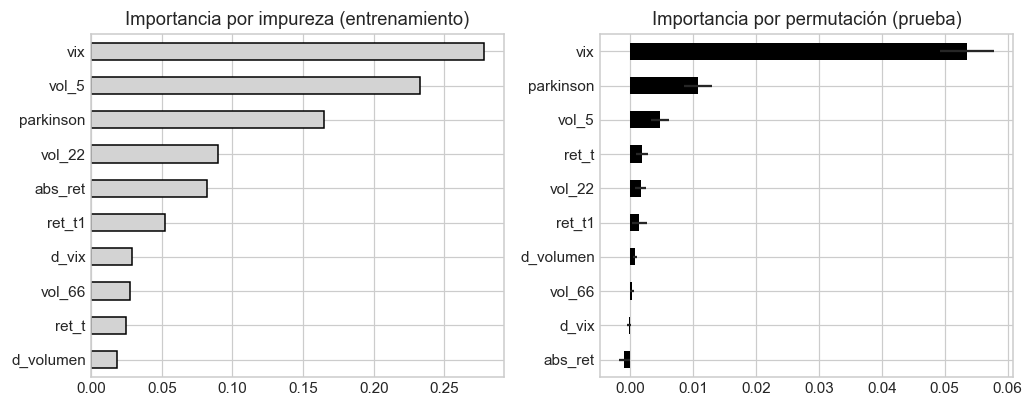

In [16]:
# Importancia por impureza (del entrenamiento) frente a importancia por permutación (en la prueba) del XGBoost ajustado
imp_impureza = pd.Series(xgb_mejor.feature_importances_, index=VARS)
perm = permutation_importance(
    xgb_mejor,
    X_pru,
    y_pru,
    n_repeats=20,
    random_state=SEMILLA,
    scoring="neg_mean_absolute_error",
)
imp_perm = pd.Series(perm.importances_mean, index=VARS)
tabla_imp = pd.DataFrame(
    {
        "impureza_entren": imp_impureza,
        "permutacion_prueba_(aumento_MAE)": imp_perm,
        "desv_permutacion": perm.importances_std,
    }
).sort_values("permutacion_prueba_(aumento_MAE)", ascending=False)
print(tabla_imp.round(4))
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
imp_impureza.sort_values().plot.barh(ax=ax[0], color="lightgray", edgecolor="black")
ax[0].set_title("Importancia por impureza (entrenamiento)")
imp_perm.sort_values().plot.barh(
    ax=ax[1], color="black", xerr=perm.importances_std[np.argsort(imp_perm.values)]
)
ax[1].set_title("Importancia por permutación (prueba)")
plt.tight_layout()
plt.show()

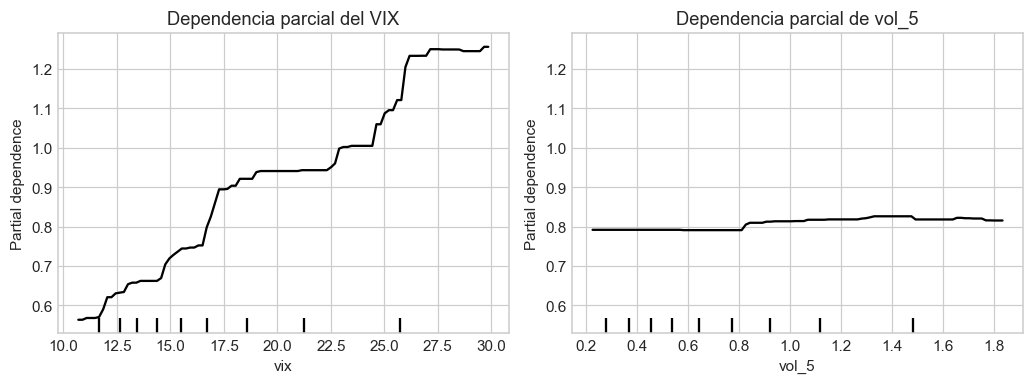

In [17]:
# Dependencia parcial: efecto marginal del VIX y de vol_5 sobre la volatilidad futura predicha
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
PartialDependenceDisplay.from_estimator(
    xgb_mejor, X_ent, ["vix", "vol_5"], ax=ax, line_kw={"color": "black"}
)
ax[0].set_title("Dependencia parcial del VIX")
ax[1].set_title("Dependencia parcial de vol_5")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el **VIX** domina en ambas medidas; **vol_5** y **parkinson** siguen. La **importancia por impureza** se calcula en el entrenamiento y favorece variables continuas con muchos cortes; la **importancia por permutación** mide cuánto **empeora el MAE de prueba** al barajar la variable, y es la que debe reportarse. Las curvas de **dependencia parcial** muestran una relación **creciente y no lineal**: el efecto del VIX se **acelera** por encima de 25–30 puntos, algo que una recta no puede expresar.

# PARTE IV — XGBoost contra el Retorno de Mañana (Mundo 1: ruido)

## 10. Un Modelo Potente No Crea Señal Donde No la Hay

In [18]:
# Mismas variables; objetivo = retorno de MAÑANA. XGBoost profundo (sobreajuste) y XGBoost regularizado
base_r = base.copy()
base_r["objetivo"] = r.shift(-1).reindex(base.index)
base_r = base_r.dropna()
ent_r, pru_r = base_r.iloc[:corte], base_r.iloc[corte:]
xgb_prof = XGBRegressor(
    n_estimators=600, learning_rate=0.1, max_depth=8, random_state=SEMILLA, n_jobs=-1
).fit(ent_r[VARS], ent_r["objetivo"])
xgb_reg = XGBRegressor(**bus_xgb.best_params_, random_state=SEMILLA, n_jobs=-1).fit(
    ent_r[VARS], ent_r["objetivo"]
)
for nombre, m in [
    ("XGBoost profundo (depth 8)", xgb_prof),
    ("XGBoost regularizado", xgb_reg),
]:
    pe, pp = m.predict(ent_r[VARS]), m.predict(pru_r[VARS])
    print(
        f"{nombre:28s}: R² entrenamiento = {r2_score(ent_r['objetivo'], pe):+.4f} | "
        f"R² prueba = {r2_score(pru_r['objetivo'], pp):+.4f} | "
        f"MAE prueba = {mean_absolute_error(pru_r['objetivo'], pp):.4f} | acierto de "
        f"signo = {np.mean(np.sign(pp) == np.sign(pru_r['objetivo'])):.3f}"
    )
print(
    "Referencia 0: MAE prueba = "
    f"{mean_absolute_error(pru_r['objetivo'], np.zeros(len(pru_r))):.4f}"
)

XGBoost profundo (depth 8)  : R² entrenamiento = +1.0000 | R² prueba = -0.1745 | MAE prueba = 0.7836 | acierto de signo = 0.517
XGBoost regularizado        : R² entrenamiento = +0.1188 | R² prueba = -0.0009 | MAE prueba = 0.7211 | acierto de signo = 0.535
Referencia 0: MAE prueba = 0.7166


**Interpretación de resultados:** el XGBoost **profundo** alcanza un **R² de entrenamiento alto** (memoriza el ruido) y un **R² de prueba negativo**; el **regularizado** apenas memoriza y en prueba tampoco supera a la referencia **0**. **Moraleja:** la potencia del modelo **no sustituye** a la señal; con el **retorno diario** ningún modelo de esta guía supera al pronóstico ingenuo, y un R² de entrenamiento alto es una **alarma**, no un logro.

## 11. Actividad Autónoma

1. Repita la Parte III con el objetivo a **22 días** y `gap = 22`. ¿Cambia el orden de los modelos?
2. En la búsqueda de XGBoost agregue `gamma` (0, 1, 5) y compare el mejor MAE de validación.
3. Entrene LightGBM con `num_leaves` = 4, 8, 31 y 127 y dibuje la curva de R² de entrenamiento y prueba, como en la sección 5.

**Entregable:** notebook ejecutado con la tabla final de la sección 8 para el horizonte de 22 días y un párrafo (≤ 150 palabras) que explique a un gestor por qué el modelo subestima los picos de volatilidad.